# Question 7 — Combien de types de terroir sur le domaine ?

## Context
Aujourd'hui, les 220 parcelles reçoivent toutes le même traitement : même densité de plantation, mêmes apports, mêmes traitements. Pourtant, elles ne sont pas placées dans les mêmes conditions naturelles : 
le sol, l'altitude, la pente, l'exposition et la pluie changent d'une parcelle à l'autre.

La direction veut savoir si ces différences permettent de former quelques groupes de parcelles qui se ressemblent. Si oui, combien de groupes, et à quoi correspond chacun d'eux.
Autrement dit, on cherche à **regrouper les parcelles selon leurs conditions naturelles**, sans savoir à l'avance combien de groupes on va trouver.

sur ces donnée : 

In [3]:
import os, pandas as pd

path = "../data/processed/parcelles_clean.csv"
df = pd.read_csv(path)


Dans un premier temps, j'analyse les 7 nombres essentiels (plus l'effectif) des 3 variables numériques du terroir :

In [5]:
num_terroir = ["altitude_m", "pente_pct", "pluviometrie_mm"]
print("Variables numériques de terroir")
display(df[num_terroir].describe().round(2))


Variables numériques de terroir


,altitude_m,pente_pct,pluviometrie_mm
count,220.00,220.00,212.00
mean,185.46,6.40,642.52
std,58.38,4.66,84.64
min,70.00,0.30,435.00
25%,146.00,2.70,586.00
50%,184.00,5.50,646.00
75%,228.25,8.52,699.00
max,340.00,28.00,895.00


On fait la répartition des types de sol et des expositions (valeurs manquantes comprises) et
on vérifie si certaines catégories sont très rares et combien de parcelles sont incomplètes, afin de décider comment les traiter avant de regrouper les terroirs.

In [10]:
cat_terroir = ["type_sol", "exposition"]
for col in cat_terroir:
    print(f"\n{col}")
    eff = df[col].value_counts(dropna=False)
    pct = (df[col].value_counts(dropna=False, normalize=True) * 100).round(1)
    display(pd.DataFrame({"effectif": eff, "part_%": pct}))


type_sol


,effectif,part_%
type_sol,,
argilo-calcaire,69,31.4
sableux,58,26.4
caillouteux,52,23.6
limoneux,41,18.6



exposition


,effectif,part_%
exposition,,
sud,74,33.6
sud-est,65,29.5
est,52,23.6
nord,21,9.5
NaN,8,3.6


Maintenant, on regarde l'altitude, la pente et la pluie avec des boîtes à moustaches pour voir où vit la majorité des parcelles et vérifier si celles qui sortent du lot ne forment pas déjà un terroir particulier

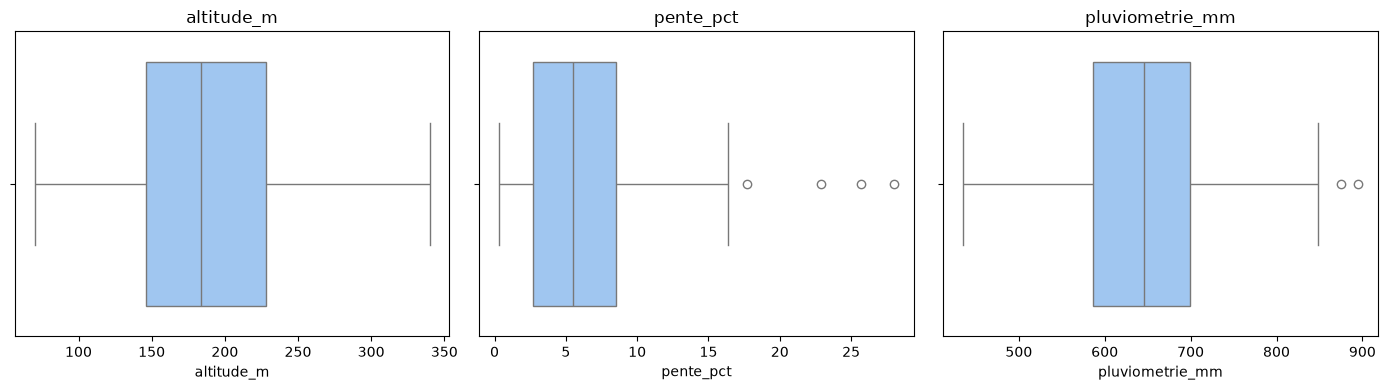

 altitude_m : seuils [22.6 ; 351.6] -> 0 parcelles au-delà
 pente_pct : seuils [-6.0 ; 17.3] -> 4 parcelles au-delà
 pluviometrie_mm : seuils [416.5 ; 868.5] -> 2 parcelles au-delà


In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, num_terroir):
    sns.boxplot(x=df[col], ax=ax, color="#93c5fd")
    ax.set_title(col)
plt.tight_layout()
plt.show()

for col in num_terroir:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    seuil_bas = q1 - 1.5 * iqr
    seuil_haut = q3 + 1.5 * iqr
    
    extremes = df[(df[col] < seuil_bas) | (df[col] > seuil_haut)]
    print(f" {col} : seuils [{seuil_bas:.1f} ; {seuil_haut:.1f}] -> {len(extremes)} parcelles au-delà")
    

Maintenant, on compare nos variables de terroir entre elles, on regarde si chaque type de sol, chaque exposition correspond déjà à une altitude, une pente ou une pluie particulière.
On découpe aussi l'altitude et la pente en tranches simples pour repérer des écarts qu'une moyenne globale écraserait.

In [17]:
print("Moyennes du terroir par type de sol")
display(df.groupby("type_sol")[num_terroir].mean().round(1))

print("Moyennes du terroir par exposition")
display(df.groupby("exposition")[num_terroir].mean().round(1))

print("Croisement type de sol x exposition")
display(pd.crosstab(df["type_sol"], df["exposition"], margins=True))

df_temp = df.copy()
df_temp["tranche_altitude"] = pd.cut(
    df_temp["altitude_m"],
    bins=[0, 140, 185, 230, 400],
    labels=["< 140 m", "140 - 185 m", "185 - 230 m", "> 230 m"]
)
df_temp["tranche_pente"] = pd.cut(
    df_temp["pente_pct"],
    bins=[0, 3, 6, 10, 35],
    labels=["Plat (< 3%)", "Doux (3-6%)", "Coteau (6-10%)", "Fort (> 10%)"]
)

print("Répartition des sols (%) par tranche d'altitude")
display((pd.crosstab(df_temp["tranche_altitude"], df_temp["type_sol"], normalize="index") * 100).round(1))

print("Répartition des sols (%) par tranche de pente")
display((pd.crosstab(df_temp["tranche_pente"], df_temp["type_sol"], normalize="index") * 100).round(1))

Moyennes du terroir par type de sol


,altitude_m,pente_pct,pluviometrie_mm
type_sol,,,
argilo-calcaire,182.8,6.9,659.3
caillouteux,182.0,5.8,636.1
limoneux,196.4,6.0,635.7
sableux,184.0,6.7,632.9


Moyennes du terroir par exposition


,altitude_m,pente_pct,pluviometrie_mm
exposition,,,
est,188.5,5.8,641.9
nord,175.9,6.2,633.2
sud,186.4,5.6,639.9
sud-est,184.4,7.6,644.0


Croisement type de sol x exposition


exposition,est,nord,sud,sud-est,All
type_sol,,,,,
argilo-calcaire,10,5,26,22,63
caillouteux,12,6,17,17,52
limoneux,11,2,15,13,41
sableux,19,8,16,13,56
All,52,21,74,65,212


Répartition des sols (%) par tranche d'altitude


type_sol,argilo-calcaire,caillouteux,limoneux,sableux
tranche_altitude,,,,
< 140 m,23.4,29.8,17.0,29.8
140 - 185 m,40.9,16.7,15.2,27.3
185 - 230 m,31.5,24.1,14.8,29.6
> 230 m,26.4,26.4,28.3,18.9


Répartition des sols (%) par tranche de pente


type_sol,argilo-calcaire,caillouteux,limoneux,sableux
tranche_pente,,,,
Plat (< 3%),30.6,29.0,16.1,24.2
Doux (3-6%),28.1,28.1,21.1,22.8
Coteau (6-10%),31.2,18.8,21.9,28.1
Fort (> 10%),37.8,16.2,13.5,32.4


,altitude_m,pente_pct,pluviometrie_mm,est_ouest_km,nord_sud_km,rendement_kg_ha
altitude_m,1.00,-0.04,0.02,0.07,0.08,-0.21
pente_pct,-0.04,1.00,-0.13,-0.01,0.09,-0.34
pluviometrie_mm,0.02,-0.13,1.00,-0.06,-0.11,0.38
est_ouest_km,0.07,-0.01,-0.06,1.00,0.06,0.07
nord_sud_km,0.08,0.09,-0.11,0.06,1.00,-0.09
rendement_kg_ha,-0.21,-0.34,0.38,0.07,-0.09,1.00


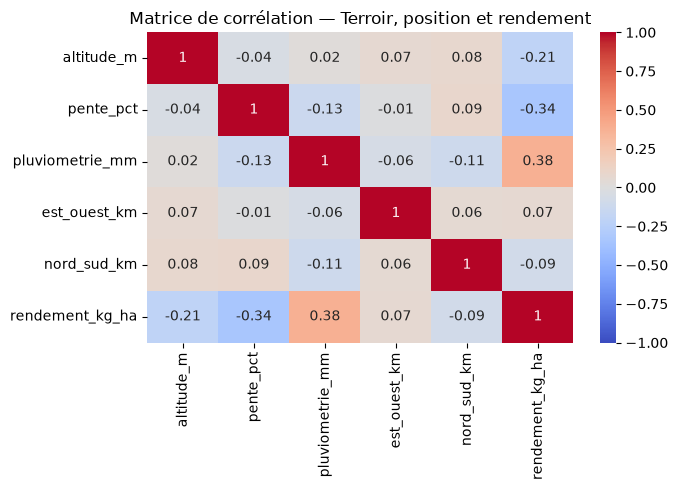

In [18]:
df_valide = df[~df["rendement_nul_a_verifier"]]

cols_corr = ["altitude_m", "pente_pct", "pluviometrie_mm", "est_ouest_km", "nord_sud_km", "rendement_kg_ha"]
mat_corr = df_valide[cols_corr].corr().round(2)

display(mat_corr)

plt.figure(figsize=(7, 5))
sns.heatmap(mat_corr, annot=True, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Matrice de corrélation — Terroir, position et rendement")
plt.tight_layout()
plt.show()

Après analyse de ces données, voici mes hypothèses avant de lancer un algorithme :

H1: Je pense qu'un terroir ne dépend pas que du type de sol, mais d'un mélange de critères indépendants. On peut voir que les moyennes d'altitude (182 à 196 m), de pente (5,8 à 6,9 %) et de pluie (633 à 659 mm) bougent très peu selon le sol, et leurs corrélations entre elles sont quasi nulles (-0,13 à +0,02). Donc je garde les 5 variables de terroir dans le clustering pour voir ce qui sépare vraiment les groupes.   

H2: Je pense que le relief et la pluie jouent un vrai rôle et que les parcelles très pentues sont un profil à part, pas des erreurs car la pente est tirée vers le haut (moyenne à 6,4 % contre 5,5 % en médiane, avec 4 parcelles au-delà de 17,3 %), et la pluie (+0,38), la pente (-0,34) et l'altitude (-0,21) sont toutes liées au rendement donc je conserve ces valeurs extrêmes pour voir si le clustering les isole ou les rattache à un groupe.   

H3: Je pense que les terroirs ne suivent pas la carte géographique et se résument à 3 ou 4 grands profils car les corrélations avec la position (est_ouest_km, nord_sud_km) sont presque nulles (-0,11 à +0,09), les 4 sols sont bien répartis (18,6 % à 31,4 %) et plus de 63 % des parcelles sont exposées sud ou sud-est, je vais tester plusieurs nombres de clusters pour retenir le découpage le plus clair.

Comme la pluie n'est presque pas liée à la position (-0,06 et -0,11) ni à l'altitude (0,02), estimer les valeurs manquantes grâce aux parcelles voisines n'a pas de sens. 
Je remplace donc les 8 pluies manquantes par la médiane (646 mm, plus robuste aux valeurs extrêmes) et les 8 expositions manquantes par la catégorie majoritaire (sud).